# Сравниваем методы для Out of Distribution Detection

* Датасет BNCI2014_001, 2-6 сек. из записи
* Обучаем на left_hand/right_hand, тестируем на всех классах, feet/tongue модель должна определить как OOD.
* Дополнительно, кроме cross-session добавила режим, когда обучение проходит на данных других участников + обучающей сессии выбранного участника.


In [1]:
import os
from pathlib import Path

DATA_ROOT = Path.home() / "mne_data"
DATA_ROOT.mkdir( parents=True, exist_ok=True )
os.environ.setdefault( "MNE_DATA", str( DATA_ROOT ) )
os.environ.setdefault( "MNE_DATASETS_BNCI_PATH", str( DATA_ROOT ) )
os.environ.setdefault( "MNE_DONTWRITE_HOME", "true" )

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns

from moabb.datasets import BNCI2014_001
from moabb.pipelines.features import AugmentedDataset
from moabb.pipelines.utils import FilterBank

from pyriemann.estimation import Covariances
from pyriemann.spatialfilters import CSP
from pyriemann.tangentspace import TangentSpace

from sklearn.base import BaseEstimator, clone
from sklearn.covariance import EllipticEnvelope, LedoitWolf
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler, normalize
from sklearn.svm import OneClassSVM, SVC
from sklearn.utils.validation import check_array, check_is_fitted

mne.set_log_level( "WARNING" )

/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/optuna/integration/sklearn.py:14: FutureWarning: `optuna.integration.sklearn` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `optuna_integration.sklearn` instead.
  optuna_warn(f"{msg} Use `optuna_integration.sklearn` instead.", FutureWarning)


## Для обучения используем: 
* Для cross-session сессию участника 0train
  * 75% для обучения
  * 25% для калибрации порога (threshold)
* Для combined
  * Для обучения: 75% сессии участника 0train + такое же количество trials других участников (их сессий 0train и 1test)
  * 25%  сессии участника 0train для калибрации порога

In [2]:
dataset = BNCI2014_001( artifact_handling="ignore" )
ALL_EVENTS = dataset.event_id
ALL_CLASSES = tuple( ALL_EVENTS )
HAND_CLASSES = ( "left_hand", "right_hand" )
HAND_EVENTS = { label: ALL_EVENTS[ label ] for label in HAND_CLASSES }

ALL_DIRECTIONS = [ ( "0train", "1test" ), ( "1test", "0train" ) ]

In [3]:
def prepare_session( runs, event_id, fmin=8, fmax=32 ):
    X, y = [], []
    code_to_label = { code: label for label, code in event_id.items() }

    for run in sorted( runs, key=int ):
        raw = runs[ run ].copy().filter( fmin, fmax, method="iir", picks="data", verbose=False )
        events = mne.find_events( raw, stim_channel="STI", shortest_event=1, verbose=False )
        epochs = mne.Epochs( raw, events, event_id, tmin=2, tmax=6, baseline=None, picks="eeg", proj=False, event_repeated="drop",  verbose=False )
        X.append( epochs.get_data() * dataset.unit_factor )
        y.extend( code_to_label[ code ] for code in epochs.events[ :, 2 ] )

    return np.concatenate( X ), np.array( y )

BANDS = [ ( 8, 12 ), ( 12, 16 ), ( 16, 20 ), ( 20, 24 ), ( 24, 28 ), ( 28, 32 ) ]

def prepare_filterbank( runs, event_id ):
    data = [ prepare_session( runs, event_id, fmin, fmax ) for fmin, fmax in BANDS ]
    return np.stack( [ X for X, _ in data ], axis=-1 ), data[ 0 ][ 1 ]


def train( train_data, calibration_data, preproc, detector ):
    X_train, y_train = train_data
    X_cal, _ = calibration_data

    fitted_model = make_pipeline( clone( preproc ), clone( detector ) ).fit( X_train, y_train )

    ood_cal = -fitted_model.score_samples( X_cal )
    threshold = np.quantile( ood_cal, 0.95 )

    return fitted_model, threshold, ood_cal

def predict( session, model ):
    X_test, _ = session
    ood_score = -model.score_samples( X_test )
    return ood_score

def evaluate( train_data, calibration_data, test_data, preproc, detector, model_name, subject, known_classes, training_mode ):
    rows, predictions = [], []

    fitted_model, threshold, ood_cal = train( train_data, calibration_data, preproc, detector )
    y_test = test_data[ 1 ]
    ood_score = predict( test_data, fitted_model )
    
    known = np.isin( y_test, known_classes )
    unknown = ~known

    is_reject = ood_score > threshold
    accepted = ~is_reject

    # find best threshold after test (just for info, not used)
    thresholds = np.r_[ np.unique( ood_score )[ ::-1 ], -np.inf ]
    best_threshold = max( thresholds, key=lambda t: accuracy_score( unknown, ood_score > t ) )
    best_reject = ood_score > best_threshold

    info = { 
        "subject": str( subject ), 
        "model": model_name,
        "training_mode": training_mode
    }

    rows.append( {
        **info,
        "n_train": len( train_data[ 1 ] ),
        "n_calibration": len( calibration_data[ 1 ] ),
        "n_test": len( y_test ),
        "n_unknown": int( ( ~known ).sum() ),
        "threshold": threshold,
        "ID_false_reject": is_reject[ known ].mean(),
        "OOD_rejection": is_reject[ unknown ].mean(),
        "OOD_false_accept": accepted[ unknown ].mean(),
        "accepted%": accepted.mean(),
        "OOD_AUROC": roc_auc_score( unknown, ood_score ),
        "OOD_accuracy": accuracy_score( unknown, is_reject ),
        "best_threshold": best_threshold,
        "best_cal_percentile": 100 * ( ood_cal <= best_threshold ).mean(),
        "best_OOD_accuracy": accuracy_score( unknown, best_reject ),
        "best_ID_false_reject": best_reject[ known ].mean(),
        "best_OOD_rejection": best_reject[ unknown ].mean(),
    } )

    predictions.append( pd.DataFrame( {
        **info,
        "true_label": y_test,
        "is_known": known,
        "ood_score": ood_score,
        "is_reject": is_reject
    } ) )
    return rows, predictions

## Проверяемые методы: 

* Извлечение признаков: ACM+TS (также с PCA), FBCSP
* Детекция OOD:
  * Методы из https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_anomaly_comparison.html: 
    * Robust covariance, One-Class SVM, One-Class SVM (SGD), Isolation Forest, Local Outlier Factor
  * Дополнительно KNN и Mahalanobis distance

In [4]:
HANDS_DIRECTIONS = [ ( "0train", "1test" ) ]

preprocs = {
    "ACM+TS ": make_pipeline(
        AugmentedDataset( order=3, lag=9 ),
        Covariances( estimator="cov" ),
        TangentSpace( metric="riemann" )
    ),
    "ACM+TS+PCA ": make_pipeline(
        AugmentedDataset( order=3, lag=9 ),
        Covariances( estimator="cov" ),
        TangentSpace( metric="riemann" ),
        PCA( n_components=10, svd_solver="full" )
    ),
    "FBCSP ": make_pipeline(
            FilterBank( make_pipeline(
            Covariances( estimator="oas" ),
            CSP( nfilter=8 )
        ) ),
        SelectKBest( mutual_info_classif, k=10 )
    )
}


class KNNDistance( BaseEstimator ):
    def __init__( self, n_neighbors=20 ):
        self.n_neighbors = n_neighbors

    def fit( self, X, y=None ):
        X = check_array( X )
        self.n_features_in_ = X.shape[ 1 ]
        self.neighbors_ = NearestNeighbors( n_neighbors=min( self.n_neighbors, len( X ) ) ).fit( X )
        return self

    def score_samples( self, X ):
        check_is_fitted( self, "neighbors_" )
        X = check_array( X )
        return -self.neighbors_.kneighbors( X )[ 0 ][ :, -1 ]

class ClassMahalanobis( BaseEstimator ):
    def fit( self, X, y ):
        self.classes_, labels = np.unique( y, return_inverse=True )
        self.means_ = np.array( [
            X[ labels == c ].mean( axis=0 )
            for c in range( len( self.classes_ ) )
        ] )
        self.covariance_ = LedoitWolf( assume_centered=True ).fit( X - self.means_[ labels ] )
        return self

    def score_samples( self, X ):
        return -np.min( [
            self.covariance_.mahalanobis( X - mean )
            for mean in self.means_
        ], axis=0 )

detectors = {
    "Robust covariance": EllipticEnvelope(),
    "One-Class SVM": OneClassSVM( kernel="rbf" ),
    "One-Class SVM + scaler":  make_pipeline(
            StandardScaler(),
            OneClassSVM( kernel="rbf" ),
        ),
    "One-Class SVM + norm": make_pipeline(
            Normalizer(),
            OneClassSVM( kernel="rbf" ),
        ),
    "One-Class SVM (SGD)": make_pipeline(
            Nystroem(),
            SGDOneClassSVM(),
        ),
    "Isolation Forest": IsolationForest(), 
    "Local Outlier Factor": LocalOutlierFactor( novelty=True ),
    "LOF cosine": LocalOutlierFactor( metric="cosine", novelty=True ),
    "LOF + norm": make_pipeline(
            Normalizer(),
            LocalOutlierFactor( novelty=True ),
        ),
    "KNN Distance": make_pipeline( 
            Normalizer(), 
            KNNDistance() 
        ),
    "Mahalanobis": make_pipeline( 
            Normalizer(),
            ClassMahalanobis() 
        ),
}

def divide_data( raw_sessions, prepare=prepare_session):
        X, y = prepare( raw_sessions[ "0train" ], HAND_EVENTS )
        X_train, X_cal, y_train, y_cal = train_test_split( X, y, test_size=0.25, stratify=y, random_state=42 )
        train_data = ( X_train, y_train )
        calibration_data = ( X_cal, y_cal )
        test_data = prepare( raw_sessions[ "1test" ], ALL_EVENTS )
        return train_data, calibration_data, test_data

# adds data from other subjects to the train data
def combine_train_data( train_data, subject, prepare ):
    parts = [ train_data ]
    for other_subject in dataset.subject_list:
        if other_subject == subject:
            continue
        sessions = dataset.get_data( subjects=[ other_subject ], n_jobs=1 )[ other_subject ]
        parts.extend( prepare( sessions[ session ], HAND_EVENTS ) for session in ( "0train", "1test" ) )
        del sessions

    return np.concatenate( [ X for X, _ in parts ] ), np.concatenate( [ y for _, y in parts ] )

# makes equal amount of data from each subject (with stratify)
def balance_combined_data( data, n_target ):
    X, y = data
    source = np.arange( n_target, len( y ) )
    source, _ = train_test_split( source, train_size=n_target, stratify=y[ source ] )
    selected = np.r_[ np.arange( n_target ), source ]
    return X[ selected ], y[ selected ]

### Каждый метод проверяется для cross-session и с обычением на других и текущем участнике (comdbined)

In [5]:
TRAINING_MODES = ( "cross-session", "combined" )
all_rows, all_predictions = [], []

for pname, preproc in preprocs.items():
    prepare = prepare_filterbank if pname.startswith( "FBCSP" ) else prepare_session

    for subject in dataset.subject_list:
        raw_sessions = dataset.get_data( subjects=[ subject ], n_jobs=1 )[ subject ]
        train_data, calibration_data, test_data = divide_data( raw_sessions, prepare )
        del raw_sessions

        for training_mode in TRAINING_MODES:
            fit_data = combine_train_data( train_data, subject, prepare ) if training_mode != "cross-session" else train_data
            if training_mode == "combined":
                fit_data = balance_combined_data( fit_data, len( train_data[ 1 ] ) )
            for dname, detector in detectors.items():
                if pname == "ACM+TS " and dname == "Robust covariance":
                    #print( f"{pname + dname} skipped")
                    continue
                name = pname + dname
                rows, predictions = evaluate( fit_data, calibration_data, test_data,
                    preproc, detector, name, subject, HAND_CLASSES, training_mode=training_mode )
                all_rows.extend( rows )
                all_predictions.extend( predictions )
                #print( f"{training_mode} | {subject} | {name} -- OOD_AUROC: {rows[ 0 ][ 'OOD_AUROC' ]:.3f} | OOD_accuracy: {rows[ 0 ][ 'OOD_accuracy' ]:.3f}" )

            del fit_data

    for training_mode in TRAINING_MODES:
        for dname in detectors:
            name = pname + dname
            scores = ( f"{row[ 'OOD_AUROC' ]:.2f}" for row in all_rows if row[ "model" ] == name and row[ "training_mode" ] == training_mode )
            print( f"{training_mode} | {name} | OOD_AUROC:", *scores )

cross-session | ACM+TS Robust covariance | OOD_AUROC:
cross-session | ACM+TS One-Class SVM | OOD_AUROC: 0.93 0.53 0.78 0.60 0.49 0.52 0.90 0.62 0.77
cross-session | ACM+TS One-Class SVM + scaler | OOD_AUROC: 0.92 0.53 0.72 0.67 0.48 0.53 0.82 0.66 0.75
cross-session | ACM+TS One-Class SVM + norm | OOD_AUROC: 0.23 0.50 0.25 0.36 0.56 0.45 0.20 0.68 0.31
cross-session | ACM+TS One-Class SVM (SGD) | OOD_AUROC: 0.94 0.53 0.77 0.61 0.49 0.51 0.89 0.60 0.76
cross-session | ACM+TS Isolation Forest | OOD_AUROC: 0.72 0.54 0.70 0.65 0.49 0.46 0.64 0.56 0.64
cross-session | ACM+TS Local Outlier Factor | OOD_AUROC: 0.93 0.53 0.76 0.59 0.50 0.51 0.90 0.69 0.82
cross-session | ACM+TS LOF cosine | OOD_AUROC: 0.11 0.47 0.33 0.50 0.52 0.42 0.28 0.74 0.46
cross-session | ACM+TS LOF + norm | OOD_AUROC: 0.11 0.47 0.34 0.50 0.52 0.42 0.28 0.74 0.46
cross-session | ACM+TS KNN Distance | OOD_AUROC: 0.15 0.49 0.32 0.39 0.50 0.43 0.25 0.75 0.38
cross-session | ACM+TS Mahalanobis | OOD_AUROC: 0.12 0.50 0.31 0.3

In [6]:
from pathlib import Path
import pandas as pd

notebook = Path( __vsc_ipynb_file__ )
save_dir = notebook.parent / "results"
save_dir.mkdir( exist_ok=True )
results_file = save_dir / f"results_{notebook.stem}.pkl"

print( results_file )


/Users/liza/Projects/vkr/notebooks/results/results_ood-detection_combined.pkl


In [7]:

pd.to_pickle( { "all_rows": all_rows, "all_predictions": all_predictions }, results_file )

In [8]:
saved = pd.read_pickle( results_file )
all_rows = saved[ "all_rows" ]
all_predictions = saved[ "all_predictions" ]
results = pd.DataFrame( all_rows )

In [9]:
results = pd.DataFrame( all_rows )

## Лучшие 5 моделей по AUROC
OOD accuracy и threshold это результаты полученные после обучения (при percentile 0.95).
Best OOD accuracy, best threshold, best percentile -- посчитаны уже после результатов теста (какой был бы идеальный порог). 

In [10]:
metrics = [
    "OOD_AUROC",
    "OOD_accuracy",
    "best_OOD_accuracy",
    "threshold",
    "best_threshold",
    "best_cal_percentile",
]

summary = results.groupby( [ "training_mode", "model" ], sort=False )[ metrics ].agg(
    [ "mean", "std" ]
).sort_values( by=( "OOD_AUROC", "mean" ), ascending=False )

display( summary[:5] )

OOD_AUROC           OOD_accuracy            \
                                      mean       std         mean       std   
training_mode model                                                           
cross-session FBCSP Mahalanobis   0.737831  0.157476     0.650077  0.133419   
              FBCSP LOF cosine    0.736861  0.165831     0.650849  0.140851   
              FBCSP LOF + norm    0.736647  0.165720     0.655093  0.135839   
combined      FBCSP KNN Distance  0.728384  0.180053     0.641204  0.155960   
cross-session FBCSP KNN Distance  0.727940  0.158810     0.625000  0.117480   

                                 best_OOD_accuracy            threshold  \
                                              mean       std       mean   
training_mode model                                                       
cross-session FBCSP Mahalanobis           0.704090  0.116485  22.014053   
              FBCSP LOF cosine            0.706019  0.128320   2.001934   
              FBCSP LOF + norm            0.706019  0.128437   1.386587   
combined      FBCSP KNN Distance          0.698302  0.133888   0.533558   
cross-session FBCSP KNN Distance          0.692901  0.117532   0.614964   

                                           best_threshold            \
                                       std           mean       std   
training_mode model                                                   
cross-session FBCSP Mahalanobis   6.664486      17.056587  7.616677   
              FBCSP LOF cosine    0.550813       1.662786  0.450935   
              FBCSP LOF + norm    0.160041       1.270137  0.159284   
combined      FBCSP KNN Distance  0.231983       0.442320  0.216166   
cross-session FBCSP KNN Distance  0.112072       0.539618  0.122723   

                                 best_cal_percentile             
                                                mean        std  
training_mode model                                              
cross-session FBCSP Mahalanobis            79.012346  18.008010  
              FBCSP LOF cosine             81.790123  12.661847  
              FBCSP LOF + norm             81.790123  11.712139  
combined      FBCSP KNN Distance           67.283951  30.893890  
cross-session FBCSP KNN Distance           82.407407  11.947674

## Лучшие 5 моделей по OOD accuracy

In [11]:

summary = results.groupby( [ "training_mode", "model" ], sort=False )[ metrics ].agg(
    [ "mean", "std" ]
).sort_values( by=( "OOD_accuracy", "mean" ), ascending=False )
#results[ results[ "subject" ] == "2" ]
display( summary[:5] )

OOD_AUROC           OOD_accuracy  \
                                              mean       std         mean   
training_mode model                                                         
cross-session FBCSP LOF + norm            0.736647  0.165720     0.655093   
              FBCSP LOF cosine            0.736861  0.165831     0.650849   
              FBCSP Mahalanobis           0.737831  0.157476     0.650077   
combined      FBCSP KNN Distance          0.728384  0.180053     0.641204   
cross-session FBCSP One-Class SVM + norm  0.717984  0.166840     0.640818   

                                                   best_OOD_accuracy  \
                                               std              mean   
training_mode model                                                    
cross-session FBCSP LOF + norm            0.135839          0.706019   
              FBCSP LOF cosine            0.140851          0.706019   
              FBCSP Mahalanobis           0.133419          0.704090   
combined      FBCSP KNN Distance          0.155960          0.698302   
cross-session FBCSP One-Class SVM + norm  0.131167          0.694830   

                                                    threshold            \
                                               std       mean       std   
training_mode model                                                       
cross-session FBCSP LOF + norm            0.128437   1.386587  0.160041   
              FBCSP LOF cosine            0.128320   2.001934  0.550813   
              FBCSP Mahalanobis           0.116485  22.014053  6.664486   
combined      FBCSP KNN Distance          0.133888   0.533558  0.231983   
cross-session FBCSP One-Class SVM + norm  0.124001  -4.875439  2.024433   

                                         best_threshold            \
                                                   mean       std   
training_mode model                                                 
cross-session FBCSP LOF + norm                 1.270137  0.159284   
              FBCSP LOF cosine                 1.662786  0.450935   
              FBCSP Mahalanobis               17.056587  7.616677   
combined      FBCSP KNN Distance               0.442320  0.216166   
cross-session FBCSP One-Class SVM + norm      -6.865266  3.065167   

                                         best_cal_percentile             
                                                        mean        std  
training_mode model                                                      
cross-session FBCSP LOF + norm                     81.790123  11.712139  
              FBCSP LOF cosine                     81.790123  12.661847  
              FBCSP Mahalanobis                    79.012346  18.008010  
combined      FBCSP KNN Distance                   67.283951  30.893890  
cross-session FBCSP One-Class SVM + norm           80.555556  15.150989

## Лучшие 3 модели для каждого из участников по AUROC

In [12]:
best = results.sort_values( [ "subject", "OOD_AUROC" ], ascending=[ True, False ] ).groupby( "subject" ).head( 3 )

display( best[ [ "subject", "training_mode", "model", "OOD_AUROC", "OOD_accuracy" ] ] )

,subject,training_mode,model,OOD_AUROC,OOD_accuracy
398,1,combined,FBCSP KNN Distance,0.960696,0.871528
180,1,cross-session,ACM+TS+PCA Robust covariance,0.955102,0.892361
200,1,combined,ACM+TS+PCA KNN Distance,0.954282,0.843750
205,2,cross-session,ACM+TS+PCA One-Class SVM + norm,0.616753,0.534722
212,2,cross-session,ACM+TS+PCA Mahalanobis,0.587722,0.559028
204,2,cross-session,ACM+TS+PCA One-Class SVM + scaler,0.552083,0.548611
429,3,cross-session,FBCSP LOF cosine,0.900174,0.826389
430,3,cross-session,FBCSP LOF + norm,0.899209,0.822917
425,3,cross-session,FBCSP One-Class SVM + norm,0.896074,0.812500
260,4,combined,ACM+TS+PCA One-Class SVM + norm,0.792438,0.517361


## Лучшие 3 модели для каждого из участников по OOD accuracy

In [13]:
best = results.sort_values( [ "subject", "OOD_accuracy" ], ascending=[ True, False ] ).groupby( "subject" ).head( 3 )

display( best[ [ "subject", "training_mode", "model", "OOD_AUROC", "OOD_accuracy" ] ] )

,subject,training_mode,model,OOD_AUROC,OOD_accuracy
180,1,cross-session,ACM+TS+PCA Robust covariance,0.955102,0.892361
16,1,combined,ACM+TS LOF cosine,0.953270,0.878472
17,1,combined,ACM+TS LOF + norm,0.952980,0.875000
212,2,cross-session,ACM+TS+PCA Mahalanobis,0.587722,0.559028
37,2,combined,ACM+TS LOF + norm,0.548515,0.552083
204,2,cross-session,ACM+TS+PCA One-Class SVM + scaler,0.552083,0.548611
429,3,cross-session,FBCSP LOF cosine,0.900174,0.826389
430,3,cross-session,FBCSP LOF + norm,0.899209,0.822917
425,3,cross-session,FBCSP One-Class SVM + norm,0.896074,0.812500
71,4,combined,ACM+TS One-Class SVM + scaler,0.705874,0.656250


## Сравнение cross-session и combined обучения в среднем по методам в разрезе участников. Результаты по участникам

Результаты очень сильно зависят от участников, для тех, у кого лучше получается различать классы (предыдущие эксперименты), лучше получается и выделять OOD. 

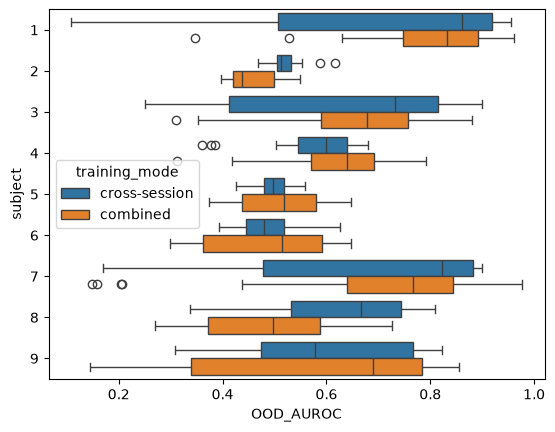

In [14]:
sns.boxplot( data=results, x="OOD_AUROC", y="subject", hue="training_mode" )
plt.show()

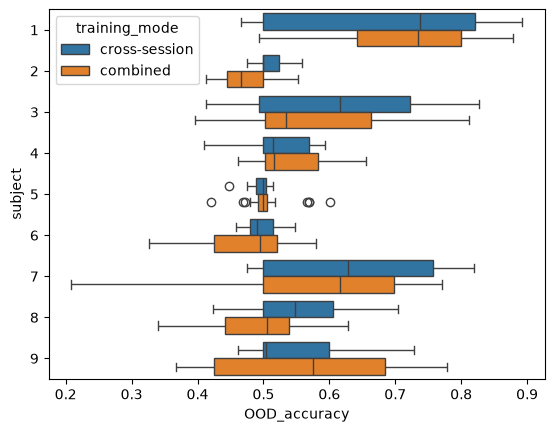

In [15]:
sns.boxplot( data=results, x="OOD_accuracy", y="subject", hue="training_mode" )
plt.show()

## Сравнение методов по среднему AUROC

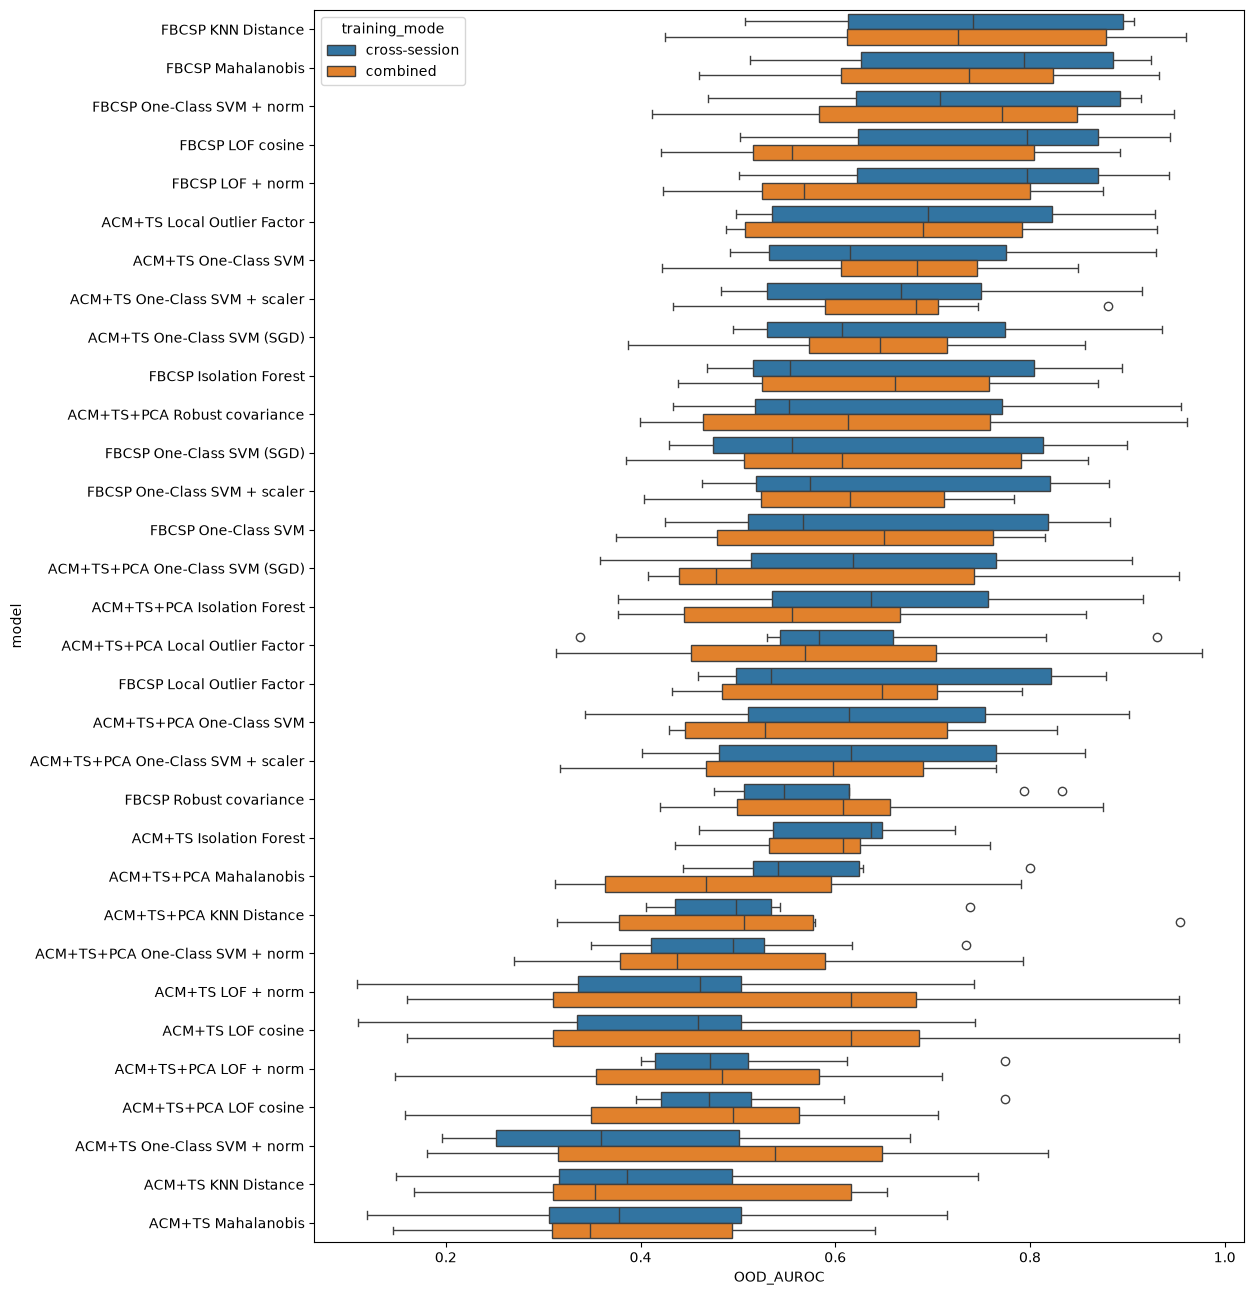

In [16]:
order = results.groupby( "model" )[ "OOD_AUROC" ].mean().sort_values( ascending=False ).index

plt.figure( figsize=(12, 16) )
sns.boxplot( data=results, x="OOD_AUROC", y="model", hue="training_mode", order=order )
plt.show()

## Сравнение методов по средней OOD accuracy

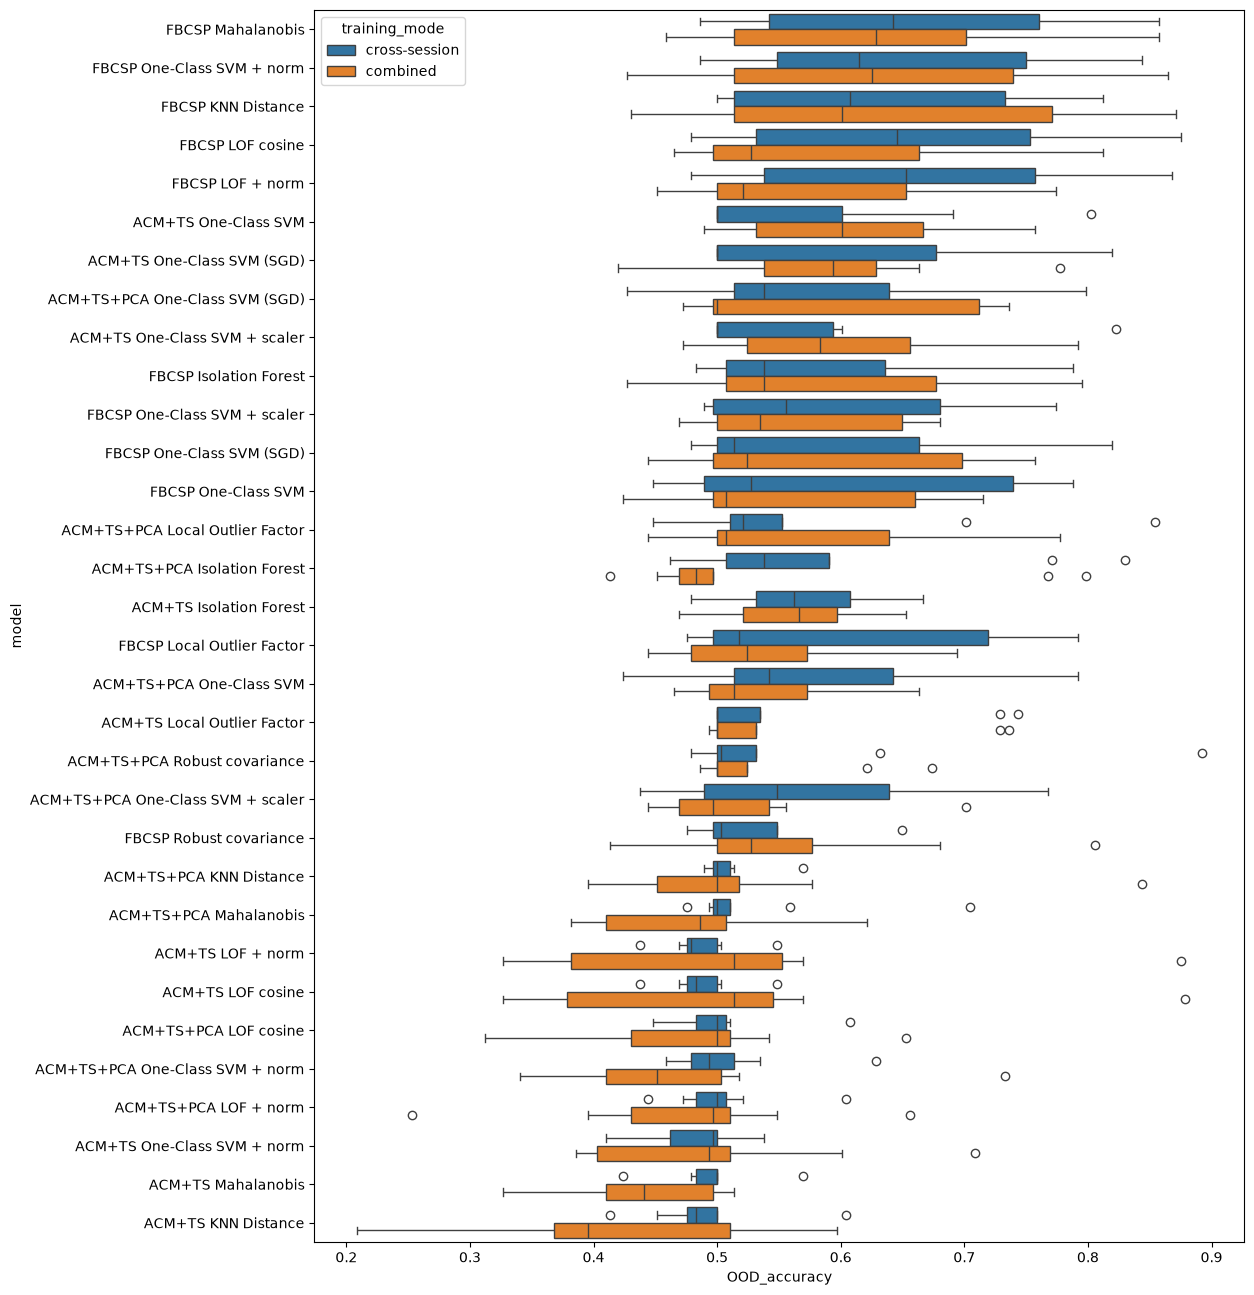

In [17]:
order = results.groupby( "model" )[ "OOD_accuracy" ].mean().sort_values( ascending=False ).index

plt.figure( figsize=(12, 16) )
sns.boxplot( data=results, x="OOD_accuracy", y="model", hue="training_mode", order=order )
plt.show()

## Разбиение по ACM+TS, ACM+TS+PCA, FBCSP для каждого метода детекции

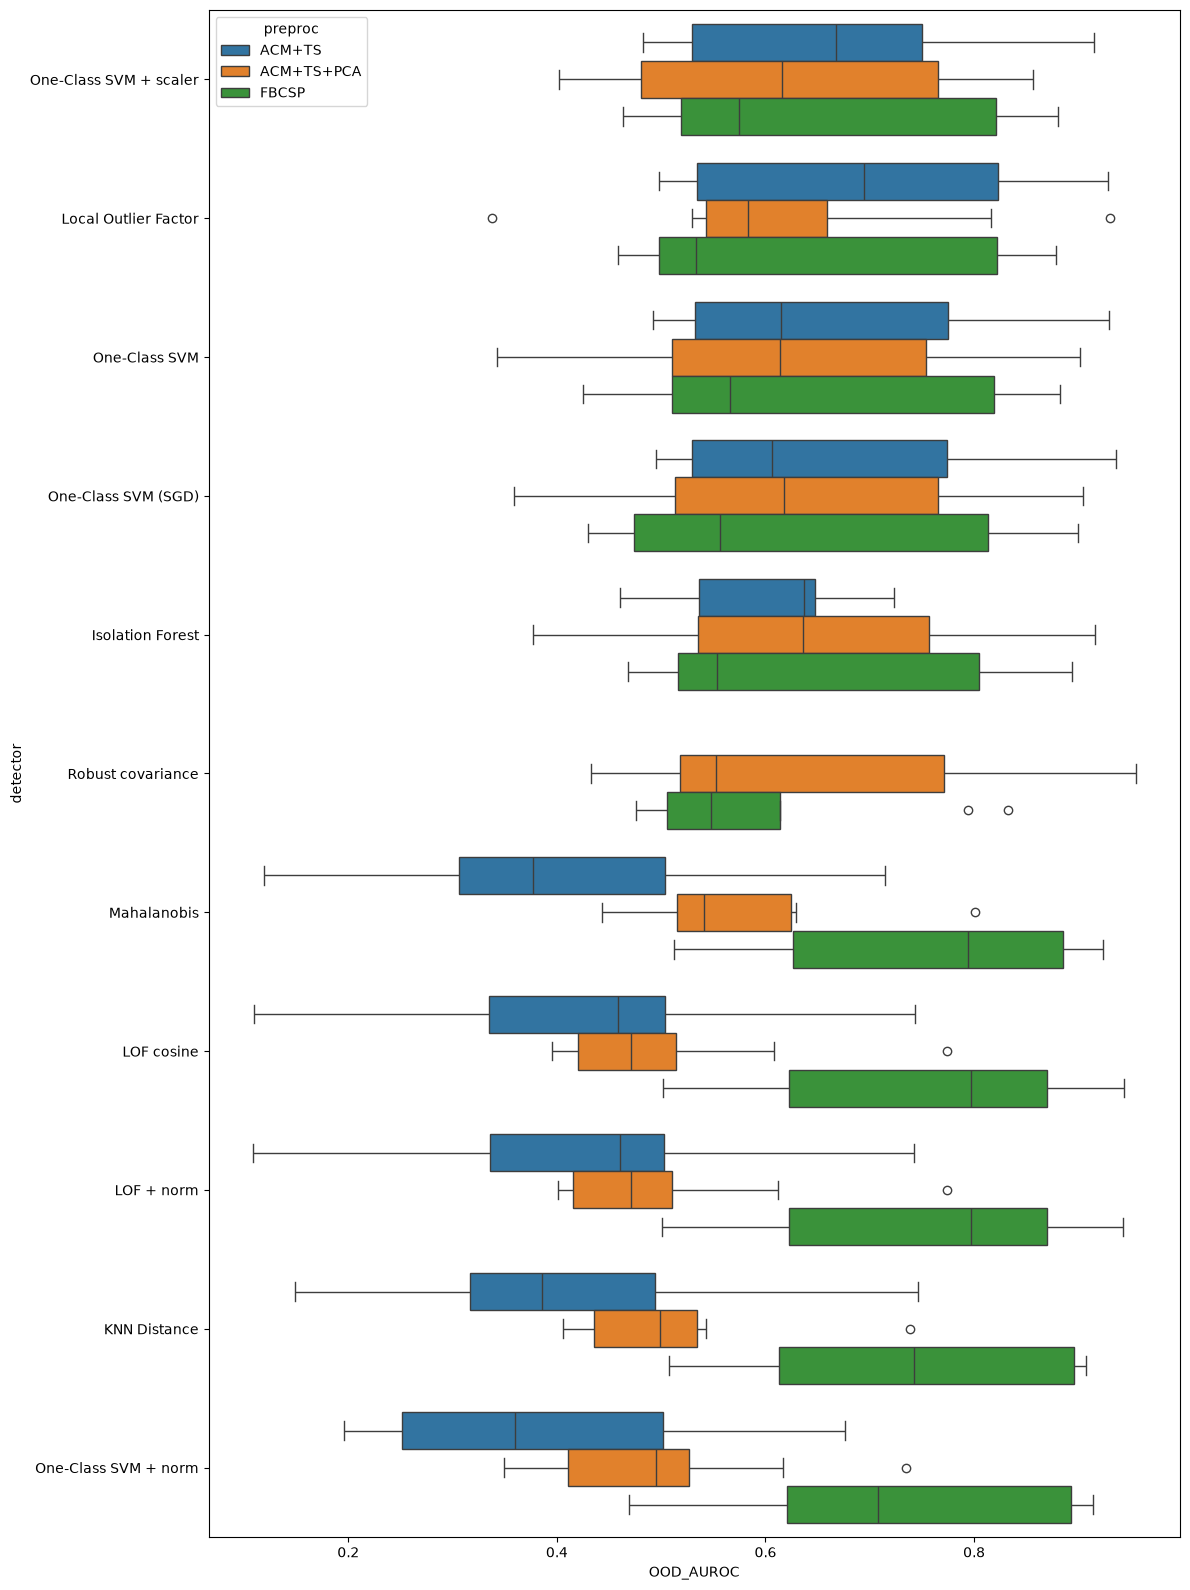

In [18]:
cross = results[ results[ "training_mode" ] == "cross-session" ].copy()
cross[ [ "preproc", "detector" ] ] = cross[ "model" ].str.split( " ", n=1, expand=True )

order = cross.groupby( "detector" )[ "OOD_AUROC" ].mean().sort_values( ascending=False ).index

plt.figure( figsize=(12, 16) )
sns.boxplot( data=cross, x="OOD_AUROC", y="detector", hue="preproc", order=order )
#plt.legend( loc="lower left" )
plt.tight_layout()
plt.show()

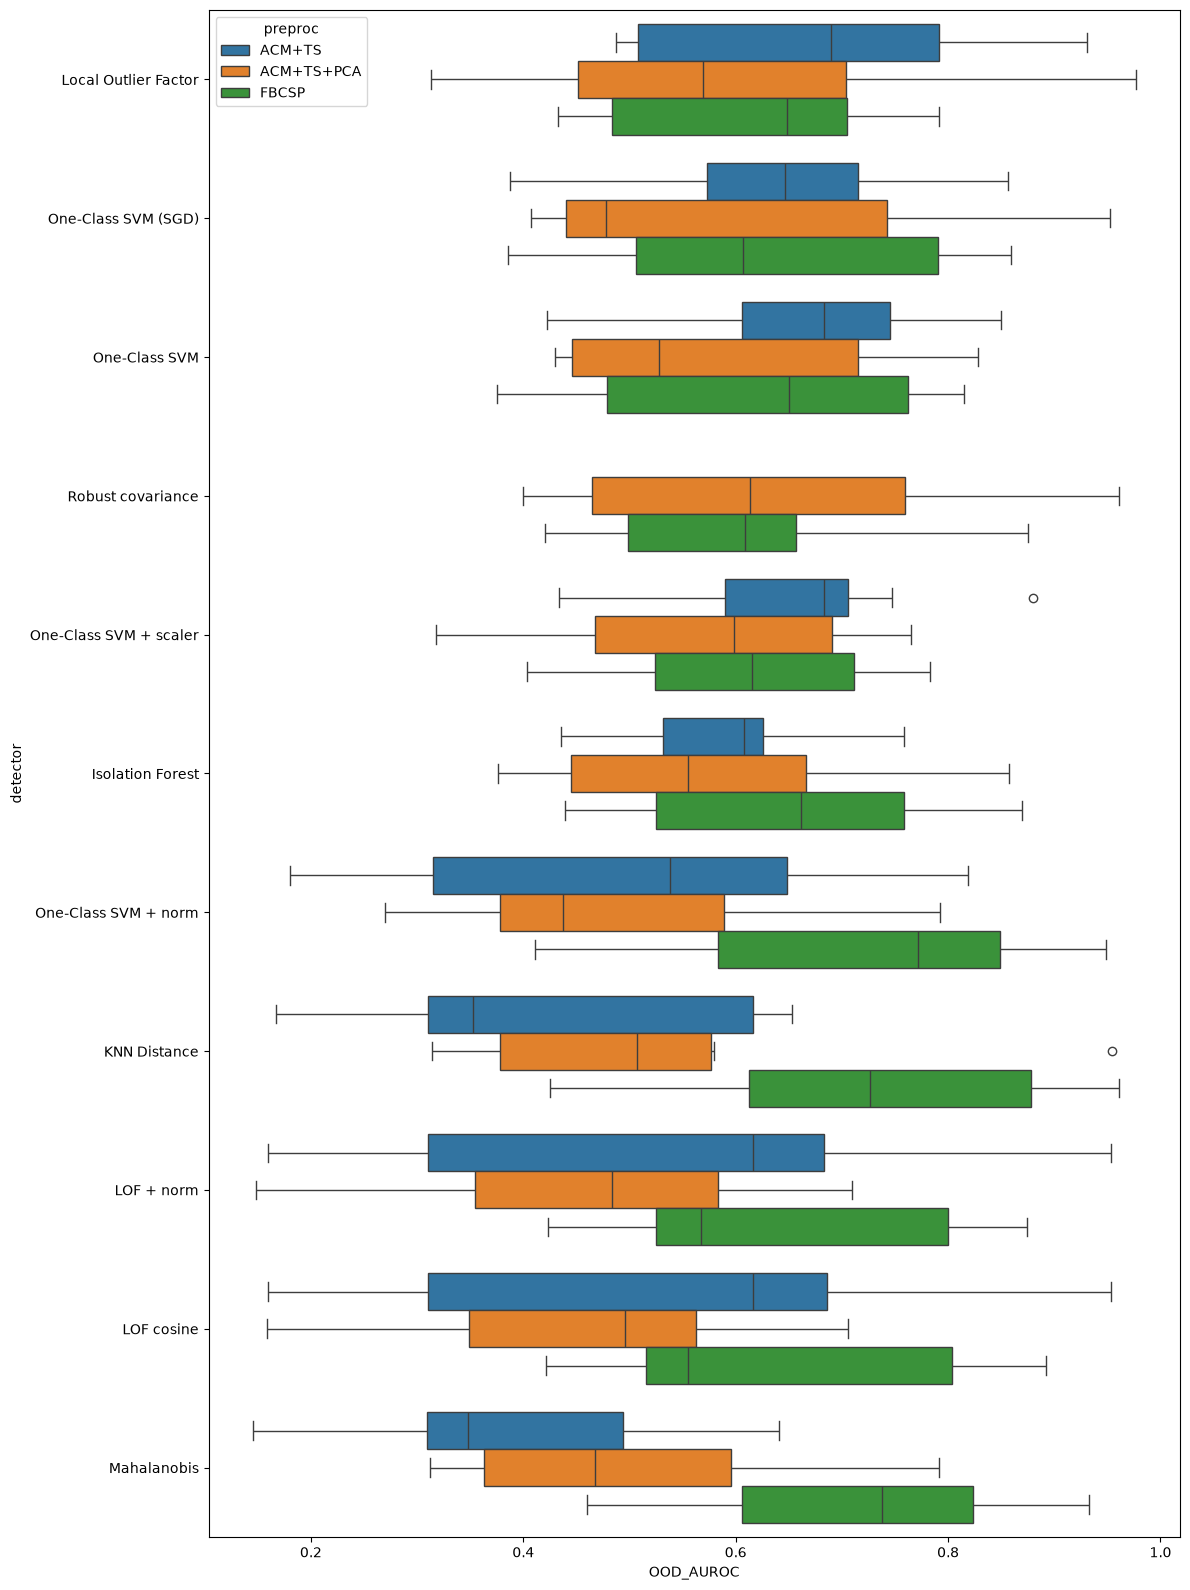

In [19]:
comb = results[ results[ "training_mode" ] == "combined" ].copy()
comb[ [ "preproc", "detector" ] ] = comb[ "model" ].str.split( " ", n=1, expand=True )

order = comb.groupby( "detector" )[ "OOD_AUROC" ].mean().sort_values( ascending=False ).index
plt.figure( figsize=(12, 16) )
sns.boxplot( data=comb, x="OOD_AUROC", y="detector", hue="preproc", order=order )
#plt.legend( loc="upper left" )
plt.tight_layout()
plt.show()

In [20]:
from itertools import combinations
from scipy.stats import wilcoxon, PermutationMethod
from statsmodels.stats.multitest import multipletests

rows = []

for detector, group in cross.groupby( "detector", sort=False ):
    table = group.pivot( index="subject", columns="preproc", values="OOD_AUROC" )

    for a, b in combinations( table.columns, 2 ):
        pair = table[ [ a, b ] ].dropna()
        diff = ( pair[ a ] - pair[ b ] ).round( 12 )
        p = 1.0 if ( diff == 0 ).all() else wilcoxon(
            diff, method=PermutationMethod( n_resamples=np.inf )
        ).pvalue

        rows.append( {
            "detector": detector, "A": a, "B": b, "n": len( pair ),
            "delta_mean": diff.mean(), "p": p
        } )

tests = pd.DataFrame( rows )
tests[ "p_holm" ] = tests.groupby( "detector" )[ "p" ].transform(
    lambda p: multipletests( p, method="holm" )[ 1 ]
)
tests[ "significant" ] = tests[ "p_holm" ] < 0.05

display( tests )

,detector,A,B,n,delta_mean,p,p_holm,significant
0,One-Class SVM,ACM+TS,ACM+TS+PCA,9,0.046939,0.074219,0.148438,False
1,One-Class SVM,ACM+TS,FBCSP,9,0.054259,0.039062,0.117188,False
2,One-Class SVM,ACM+TS+PCA,FBCSP,9,0.007320,0.820312,0.820312,False
3,One-Class SVM + scaler,ACM+TS,ACM+TS+PCA,9,0.037058,0.359375,0.750000,False
4,One-Class SVM + scaler,ACM+TS,FBCSP,9,0.036742,0.250000,0.750000,False
5,One-Class SVM + scaler,ACM+TS+PCA,FBCSP,9,-0.000316,1.000000,1.000000,False
6,One-Class SVM + norm,ACM+TS,ACM+TS+PCA,9,-0.109450,0.019531,0.058594,False
7,One-Class SVM + norm,ACM+TS,FBCSP,9,-0.326137,0.019531,0.058594,False
8,One-Class SVM + norm,ACM+TS+PCA,FBCSP,9,-0.216687,0.054688,0.058594,False
9,One-Class SVM (SGD),ACM+TS,ACM+TS+PCA,9,0.041945,0.250000,0.500000,False
